### Import Data

In [8]:
import pandas as pd
df=pd.read_csv('powerconsumption.csv')
df.head()

,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


###  Dataset structure, dimensions and column names.

In [12]:
print(f"Dataset Dimensions: {df.shape[0]} rows and {df.shape[1]} columns\n")


Dataset Dimensions: 52416 rows and 9 columns



In [14]:
 df.columns

Index(['Datetime', 'Temperature', 'Humidity', 'WindSpeed',
       'GeneralDiffuseFlows', 'DiffuseFlows', 'PowerConsumption_Zone1',
       'PowerConsumption_Zone2', 'PowerConsumption_Zone3'],
      dtype='str')

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Datetime                52416 non-null  str    
 1   Temperature             52416 non-null  float64
 2   Humidity                52416 non-null  float64
 3   WindSpeed               52416 non-null  float64
 4   GeneralDiffuseFlows     52416 non-null  float64
 5   DiffuseFlows            52416 non-null  float64
 6   PowerConsumption_Zone1  52416 non-null  float64
 7   PowerConsumption_Zone2  52416 non-null  float64
 8   PowerConsumption_Zone3  52416 non-null  float64
dtypes: float64(8), str(1)
memory usage: 4.3 MB


In [21]:
df['Datetime'] = pd.to_datetime(df['Datetime'], errors='coerce')

In [22]:

  print("New Data Type:", df['Datetime'].dtype)


New Data Type: datetime64[us]


In [23]:
  print("Failed/Invalid Conversions:", df['Datetime'].isnull().sum())

Failed/Invalid Conversions: 0


### Identify missing values, duplicate records and inconsistent data.

In [24]:
missing_count = df.isnull().sum()


In [25]:
missing_pct = (missing_count / len(df)) * 100

In [26]:
missing_df = pd.DataFrame({
    'Missing Values': missing_count,
    'Percentage (%)': missing_pct.round(2)
})


In [30]:
   print("--- MISSING VALUES SUMMARY ---")
   display(missing_df)

--- MISSING VALUES SUMMARY ---


,Missing Values,Percentage (%)
Datetime,0,0.0
Temperature,0,0.0
Humidity,0,0.0
WindSpeed,0,0.0
GeneralDiffuseFlows,0,0.0
DiffuseFlows,0,0.0
PowerConsumption_Zone1,0,0.0
PowerConsumption_Zone2,0,0.0
PowerConsumption_Zone3,0,0.0


In [37]:
    print("--- DUPLICATE RECORDS SUMMARY ---")
    exact_dups = df.duplicated().sum()
    print(f"Exact Duplicate Rows: {exact_dups}")

    time_dups = df['Datetime'].duplicated().sum()
    print(f"Duplicate Timestamps: {time_dups}")

    


--- DUPLICATE RECORDS SUMMARY ---
Exact Duplicate Rows: 0
Duplicate Timestamps: 0


In [47]:
    print('INCONSISTENT DATA')
    
    numeric_cols = [
    'Temperature', 'Humidity', 'WindSpeed', 
    'GeneralDiffuseFlows', 'DiffuseFlows', 
    'PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3'
    ]
    for col in numeric_cols:
        neg_count = (df[col] < 0).sum()
        print(f"{col}: {neg_count} negative values | Min: {df[col].min():.2f} | Max: {df[col].max():.2f}")
    invalid_humidity = (df['Humidity'] > 100).sum()
    print(f"\nHumidity > 100%: {invalid_humidity} rows")
    solar_inconsistency = (df['DiffuseFlows'] > df['GeneralDiffuseFlows']).sum()
    print(f"DiffuseFlows > GeneralDiffuseFlows: {solar_inconsistency} rows")
    for zone in ['PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']:
        zero_power = (df[zone] == 0).sum()
        print(f"{zone} == 0 kW: {zero_power} rows")

    

INCONSISTENT DATA
Temperature: 0 negative values | Min: 3.25 | Max: 40.01
Humidity: 0 negative values | Min: 11.34 | Max: 94.80
WindSpeed: 0 negative values | Min: 0.05 | Max: 6.48
GeneralDiffuseFlows: 0 negative values | Min: 0.00 | Max: 1163.00
DiffuseFlows: 0 negative values | Min: 0.01 | Max: 936.00
PowerConsumption_Zone1: 0 negative values | Min: 13895.70 | Max: 52204.40
PowerConsumption_Zone2: 0 negative values | Min: 8560.08 | Max: 37408.86
PowerConsumption_Zone3: 0 negative values | Min: 5935.17 | Max: 47598.33

Humidity > 100%: 0 rows
DiffuseFlows > GeneralDiffuseFlows: 26543 rows
PowerConsumption_Zone1 == 0 kW: 0 rows
PowerConsumption_Zone2 == 0 kW: 0 rows
PowerConsumption_Zone3 == 0 kW: 0 rows


In [48]:
df = df.sort_values('Datetime').reset_index(drop=True)

In [49]:
df['Time_Diff'] = df['Datetime'].diff()


In [50]:
   print(df['Time_Diff'].value_counts())


Time_Diff
0 days 00:10:00    52415
Name: count, dtype: int64


In [62]:
    zone_cols = ['PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']
    print("STATISTICAL OUTLIERS (IQR METHOD)")
    for col in zone_cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
    
        iqr_outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    
        print(f"\n{col}:")
        print(f"  Min: {df[col].min():,.2f} kW | Max: {df[col].max():,.2f} kW")
        print(f"  Normal IQR Range: {lower_bound:,.2f} kW to {upper_bound:,.2f} kW")
        print(f"  IQR Outliers: {len(iqr_outliers)} rows")

STATISTICAL OUTLIERS (IQR METHOD)

PowerConsumption_Zone1:
  Min: 13,895.70 kW | Max: 52,204.40 kW
  Normal IQR Range: 9,813.14 kW to 53,806.54 kW
  IQR Outliers: 0 rows

PowerConsumption_Zone2:
  Min: 8,560.08 kW | Max: 37,408.86 kW
  Normal IQR Range: 5,381.34 kW to 36,313.14 kW
  IQR Outliers: 7 rows

PowerConsumption_Zone3:
  Min: 5,935.17 kW | Max: 47,598.33 kW
  Normal IQR Range: 387.17 kW to 34,366.26 kW
  IQR Outliers: 1191 rows


In [110]:
# Show the TOP 10 Outliers in zome 3

df.nlargest(10, "PowerConsumption_Zone3")[["Datetime", "PowerConsumption_Zone3"]]

,Datetime,PowerConsumption_Zone3
29497,2017-07-24 20:10:00,47598.32636
29929,2017-07-27 20:10:00,47598.32636
29784,2017-07-26 20:00:00,47580.25105
29785,2017-07-26 20:10:00,47507.94979
29786,2017-07-26 20:20:00,47441.67364
29930,2017-07-27 20:20:00,47435.64854
29496,2017-07-24 20:00:00,47429.62343
29498,2017-07-24 20:20:00,47405.52301
29783,2017-07-26 19:50:00,47291.04603
29353,2017-07-23 20:10:00,47278.99582


In [112]:
# Save cleaned data set

df.to_csv("powerconsumption_cleaned.csv", index=False)
print("Saved. Rows and columns:", df.shape)

Saved. Rows and columns: (52416, 21)


## Summary of Results

### Data Dimensions

Dataset Dimensions: 52416 rows and 9 columns

### Data Cleaning Steps

 Missing Values : None

 Duplicate Value : None

 Inconsistent Data : No negative value, Exact 10 mins datetime diffference, About 50 % Diffuse flows> General diffuse flows

 Date time Validation: String type converted to datetime type.

### Creating  additional time-based columns

In [66]:
df['Year'] = df['Datetime'].dt.year
df['Month'] = df['Datetime'].dt.month_name()
df['Day'] = df['Datetime'].dt.day
df['Hour'] = df['Datetime'].dt.hour
df['Day_of_Week'] = df['Datetime'].dt.day_name()
df['Date'] = df['Datetime'].dt.date

display(df[['Datetime', 'Year', 'Month', 'Day', 'Hour', 'Day_of_Week', 'Date']].head())



,Datetime,Year,Month,Day,Hour,Day_of_Week,Date
0,2017-01-01 00:00:00,2017,January,1,0,Sunday,2017-01-01
1,2017-01-01 00:10:00,2017,January,1,0,Sunday,2017-01-01
2,2017-01-01 00:20:00,2017,January,1,0,Sunday,2017-01-01
3,2017-01-01 00:30:00,2017,January,1,0,Sunday,2017-01-01
4,2017-01-01 00:40:00,2017,January,1,0,Sunday,2017-01-01


### Electric Consumption Analysis

#### Creating Energy columns to give hourly consumption

In [80]:
df['Energy_Zone1_kWh'] = df['PowerConsumption_Zone1'] * (10 / 60)
df['Energy_Zone2_kWh'] = df['PowerConsumption_Zone2'] * (10 / 60)
df['Energy_Zone3_kWh'] = df['PowerConsumption_Zone3'] * (10 / 60)
df['Total_Energy_kWh'] = df['Energy_Zone1_kWh'] + df['Energy_Zone2_kWh'] + df['Energy_Zone3_kWh']


In [81]:
display(df[['Datetime','PowerConsumption_Zone1','Energy_Zone1_kWh','PowerConsumption_Zone2','Energy_Zone2_kWh','PowerConsumption_Zone3',
            'Energy_Zone3_kWh','Total_Energy_kWh']].head())

,Datetime,PowerConsumption_Zone1,Energy_Zone1_kWh,PowerConsumption_Zone2,Energy_Zone2_kWh,PowerConsumption_Zone3,Energy_Zone3_kWh,Total_Energy_kWh
0,2017-01-01 00:00:00,34055.69620,5675.949367,16128.87538,2688.145897,20240.96386,3373.493977,11737.589240
1,2017-01-01 00:10:00,29814.68354,4969.113923,19375.07599,3229.179332,20131.08434,3355.180723,11553.473978
2,2017-01-01 00:20:00,29128.10127,4854.683545,19006.68693,3167.781155,19668.43373,3278.072288,11300.536988
3,2017-01-01 00:30:00,28228.86076,4704.810127,18361.09422,3060.182370,18899.27711,3149.879518,10914.872015
4,2017-01-01 00:40:00,27335.69620,4555.949367,17872.34043,2978.723405,18442.40964,3073.734940,10608.407712


### Consumption Patterns

In [92]:
zone_kw = ['PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']
zone_kwh = ['Energy_Zone1_kWh', 'Energy_Zone2_kWh', 'Energy_Zone3_kWh']
summary = pd.DataFrame({
    'Average Power (kW)': df[zone_kw].mean().values.round(2),
    'Median Power (kW)': df[zone_kw].median().values.round(2),
    'Std Dev (kW)': df[zone_kw].std().values.round(2),
    'Min Power (kW)': df[zone_kw].min().values.round(2),
    'Max Power (kW)': df[zone_kw].max().values.round(2),
    'Total Power (GW)':(df[zone_kw].sum().values/1e6).round(2),
    'Total Energy (GWh)': (df[zone_kwh].sum().values/1e6).round(2),
    'Energy Zone Share (%)': ((df[zone_kwh].sum().values / df['Total_Energy_kWh'].sum()) * 100).round(2)
}, index=zone_labels)


In [93]:
print("1. OVERALL & AVERAGE CONSUMPTION BY ZONE")
display(summary)

1. OVERALL & AVERAGE CONSUMPTION BY ZONE


,Average Power (kW),Median Power (kW),Std Dev (kW),Min Power (kW),Max Power (kW),Total Power (GW),Total Energy (GWh),Energy Zone Share (%)
Zone 1,32344.97,32265.92,7130.56,13895.70,52204.40,1695.39,282.57,45.41
Zone 2,21042.51,20823.17,5201.47,8560.08,37408.86,1102.96,183.83,29.54
Zone 3,17835.41,16415.12,6622.17,5935.17,47598.33,934.86,155.81,25.04


In [91]:
print("\n 2. HIGHEST & LOWEST CONSUMPTION PERIODS")
for col, name in zip(zone_kw, zone_labels):
    max_row = df.loc[df[col].idxmax()]
    min_row = df.loc[df[col].idxmin()]
    print(f"{name}:")
    print(f"  Highest: {max_row[col]:,.2f} kW on {max_row['Datetime']} (Temp: {max_row['Temperature']:.1f}°C)")
    print(f"  Lowest : {min_row[col]:,.2f} kW on {min_row['Datetime']} (Temp: {min_row['Temperature']:.1f}°C)")


 2. HIGHEST & LOWEST CONSUMPTION PERIODS
Zone 1:
  Highest: 52,204.40 kW on 2017-08-07 20:20:00 (Temp: 27.2°C)
  Lowest : 13,895.70 kW on 2017-01-15 07:30:00 (Temp: 10.0°C)
Zone 2:
  Highest: 37,408.86 kW on 2017-07-24 19:40:00 (Temp: 29.8°C)
  Lowest : 8,560.08 kW on 2017-04-02 06:10:00 (Temp: 14.5°C)
Zone 3:
  Highest: 47,598.33 kW on 2017-07-24 20:10:00 (Temp: 29.1°C)
  Lowest : 5,935.17 kW on 2017-12-11 07:00:00 (Temp: 5.6°C)


In [144]:
hourly_avg = df.groupby('Hour')[zone_kw].mean()
print("\n Hourly  Power Consumption (kW) ")
display(hourly_avg.round(2))


 Hourly  Power Consumption (kW) 


,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Hour,,,
0,30217.24,19692.07,18657.22
1,27565.53,17765.08,16970.80
2,26292.69,16730.16,15981.10
3,25338.12,16052.59,15238.61
4,24633.58,15624.08,14671.04
5,23437.58,14974.91,13226.38
6,23203.60,14934.70,12051.60
7,24038.35,15719.12,11667.86
8,26583.26,17529.68,12793.79


In [95]:
hourly_avg = df.groupby('Hour')[zone_kw].mean()
hourly_avg.columns = zone_labels
print("\n 3. PEAK & OFF-PEAK HOURS (AVERAGE kW)")
for name in zone_labels:
    peak_hr = hourly_avg[name].idxmax()
    low_hr = hourly_avg[name].idxmin()
    print(f"{name}: Peak Hour = {peak_hr:02d}:00 ({hourly_avg[name].max():,.2f} kW) | Lowest Hour = {low_hr:02d}:00 ({hourly_avg[name].min():,.2f} kW)")


 3. PEAK & OFF-PEAK HOURS (AVERAGE kW)
Zone 1: Peak Hour = 20:00 (43,822.59 kW) | Lowest Hour = 06:00 (23,203.60 kW)
Zone 2: Peak Hour = 20:00 (28,186.91 kW) | Lowest Hour = 06:00 (14,934.70 kW)
Zone 3: Peak Hour = 20:00 (26,027.61 kW) | Lowest Hour = 07:00 (11,667.86 kW)


In [97]:
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekly_avg = df.groupby('Day_of_Week')[zone_kw].mean().reindex(day_order)
weekly_avg.columns = zone_labels
print("\n 4. AVERAGE POWER BY DAY OF WEEK (kW)")
display(weekly_avg.round(2))


 4. AVERAGE POWER BY DAY OF WEEK (kW)


,Zone 1,Zone 2,Zone 3
Day_of_Week,,,
Monday,32615.41,21280.07,17809.08
Tuesday,32713.03,21518.60,17831.69
Wednesday,32871.76,21627.36,17851.40
Thursday,32842.48,21845.16,17843.69
Friday,32339.00,21461.04,17545.97
Saturday,32253.03,20585.96,18011.19
Sunday,30780.08,18979.38,17954.83


In [142]:
weekly_avg = df.groupby('Day_of_Week')['Total_Energy_kWh'].mean().reindex(day_order)
print("\n DAY OF THE WEEK AVERAGE ENERGY CONSUMPTION (GWh)") 
display(weekly_avg.round(2))


 DAY OF THE WEEK AVERAGE ENERGY CONSUMPTION (GWh)


Day_of_Week
Monday       11950.76
Tuesday      12010.55
Wednesday    12058.42
Thursday     12088.56
Friday       11891.00
Saturday     11808.36
Sunday       11285.71
Name: Total_Energy_kWh, dtype: float64

In [134]:
monthly_energy = df.groupby('Month')[zone_kwh].sum() / 1e6  # in GWh
monthly_energy.columns = zone_labels
print("\n=== 5. MONTHLY TOTAL ENERGY CONSUMPTION (GWh) ===")
display(monthly_energy.round(2))


=== 5. MONTHLY TOTAL ENERGY CONSUMPTION (GWh) ===


,Zone 1,Zone 2,Zone 3
Month,,,
April,22.44,12.70,13.39
August,27.11,18.34,18.34
December,20.90,17.05,7.95
February,20.82,12.63,11.65
January,23.09,14.43,13.20
July,26.66,17.97,20.98
June,24.92,14.88,14.71
March,23.18,13.73,12.61
May,24.10,14.86,13.11


In [139]:
monthly_energy = df.groupby('Month')['Total_Energy_kWh'].sum() / 1e6  # in GWh
print("\n===6. MONTHLY TOTAL ENERGY CONSUMPTION (GWh) ===")
display(monthly_energy.round(2))


===6. MONTHLY TOTAL ENERGY CONSUMPTION (GWh) ===


Month
April        48.53
August       63.79
December     45.90
February     45.10
January      50.72
July         65.60
June         54.51
March        49.52
May          52.08
November     46.88
October      50.27
September    49.32
Name: Total_Energy_kWh, dtype: float64

###  Environmental Relationship Analysis

In [100]:
weather_cols = ['Temperature', 'Humidity', 'WindSpeed']
zone_kw = ['PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']
zone_labels = ['Zone 1', 'Zone 2', 'Zone 3']
analysis_df = df[weather_cols + zone_kw].rename(columns=dict(zip(zone_kw, zone_labels)))

pearson_corr = analysis_df.corr(method='pearson').loc[weather_cols, zone_labels]
print(" 1. PEARSON CORRELATION MATRIX (LINEAR ASSOCIATION)")
display(pearson_corr.round(3))

spearman_corr = analysis_df.corr(method='spearman').loc[weather_cols, zone_labels]
print("\n 2. SPEARMAN CORRELATION MATRIX (RANK ASSOCIATION) ")
display(spearman_corr.round(3))


 1. PEARSON CORRELATION MATRIX (LINEAR ASSOCIATION)


,Zone 1,Zone 2,Zone 3
Temperature,0.440,0.382,0.490
Humidity,-0.287,-0.295,-0.233
WindSpeed,0.167,0.146,0.279



 2. SPEARMAN CORRELATION MATRIX (RANK ASSOCIATION) 


,Zone 1,Zone 2,Zone 3
Temperature,0.433,0.379,0.436
Humidity,-0.300,-0.309,-0.212
WindSpeed,0.107,0.087,0.079


In [101]:
df['Temp_Band'] = pd.cut(
    df['Temperature'],
    bins=[0, 15, 20, 25, 30, 45],
    labels=['Cool (<15°C)', 'Mild (15–20°C)', 'Warm (20–25°C)', 'Hot (25–30°C)', 'Very Hot (>30°C)']
)

temp_summary = df.groupby('Temp_Band', observed=False)[zone_kw].mean()
temp_summary.columns = zone_labels
print("\n 3. AVERAGE POWER CONSUMPTION (kW) BY TEMPERATURE BAND")
display(temp_summary.round(2))


 3. AVERAGE POWER CONSUMPTION (kW) BY TEMPERATURE BAND


,Zone 1,Zone 2,Zone 3
Temp_Band,,,
Cool (<15°C),29024.57,19047.28,15373.46
Mild (15–20°C),31190.44,20427.71,15764.11
Warm (20–25°C),34005.29,21572.50,18369.32
Hot (25–30°C),37287.10,24486.07,24523.26
Very Hot (>30°C),39500.95,27062.10,28928.12


### Environmental Relationship Visualisation

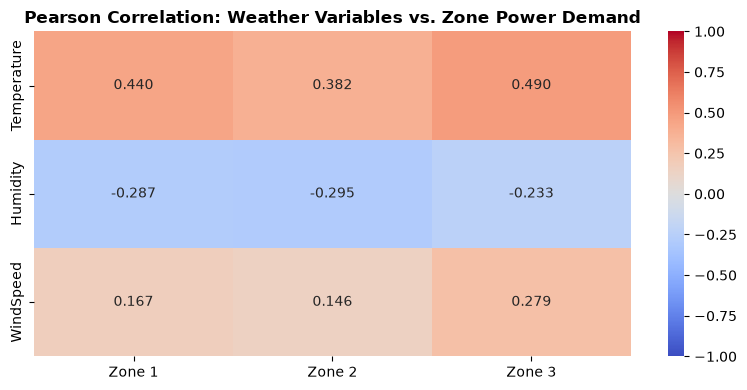

In [103]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 4))
sns.heatmap(pearson_corr, annot=True, cmap='coolwarm', center=0, vmin=-1, vmax=1, fmt='.3f')
plt.title('Pearson Correlation: Weather Variables vs. Zone Power Demand', fontweight='bold')
plt.tight_layout()
plt.show()


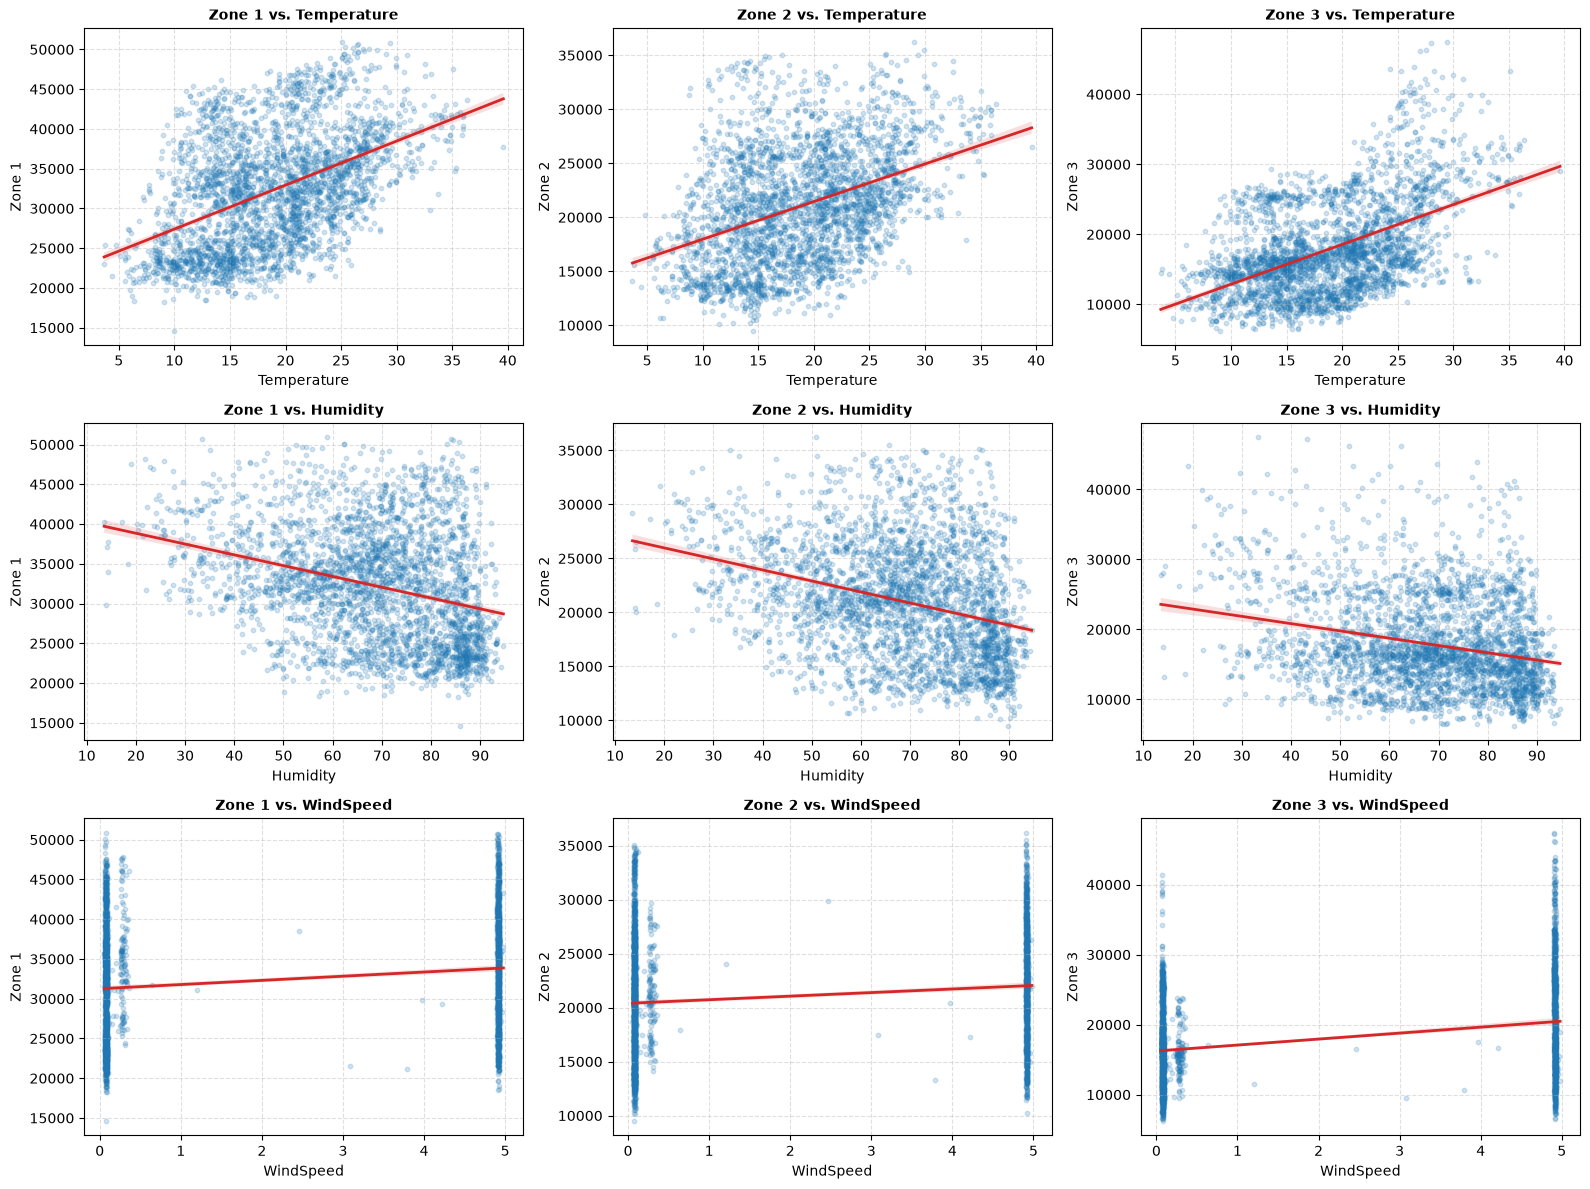

In [106]:
sample_df = analysis_df.sample(n=3000, random_state=42)
fig, axes = plt.subplots(3, 3, figsize=(16, 12))

for row_idx, weather in enumerate(weather_cols):
    for col_idx, zone in enumerate(zone_labels):
        ax = axes[row_idx, col_idx]
        sns.regplot(
            data=sample_df, x=weather, y=zone, ax=ax,
            scatter_kws={'alpha': 0.2, 's': 10, 'color': '#1f77b4'},
            line_kws={'color': '#d62728', 'linewidth': 2}
        )
        ax.set_title(f'{zone} vs. {weather}', fontsize=10, fontweight='bold')
        ax.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

### DATA VISUALIZATION

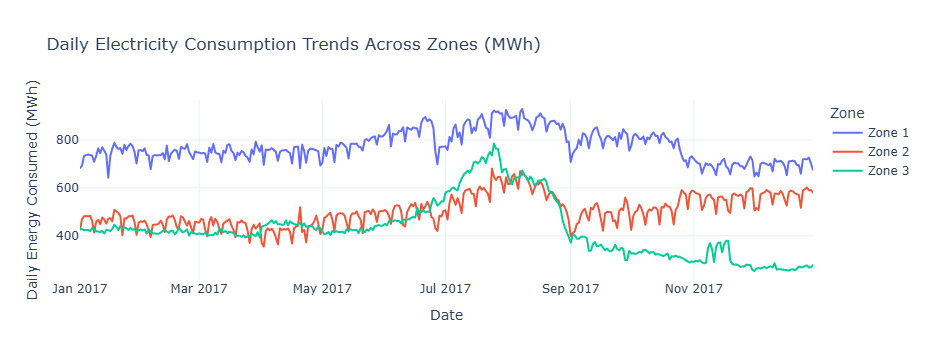

In [113]:
# Daily Energy consumption
import plotly.express as px
daily_df = df.groupby('Date')[['Energy_Zone1_kWh', 'Energy_Zone2_kWh', 'Energy_Zone3_kWh']].sum() / 1000
daily_df.columns = ['Zone 1', 'Zone 2', 'Zone 3']
daily_df = daily_df.reset_index()
daily_long = daily_df.melt(id_vars='Date', var_name='Zone', value_name='Daily_Energy_MWh')

fig = px.line(
    daily_long,
    x='Date',
    y='Daily_Energy_MWh',
    color='Zone',
    title='Daily Electricity Consumption Trends Across Zones (MWh)',
    labels={'Daily_Energy_MWh': 'Daily Energy Consumed (MWh)', 'Date': 'Date'},
    template='plotly_white'
)
fig.update_layout(hovermode='x unified')
fig.show()


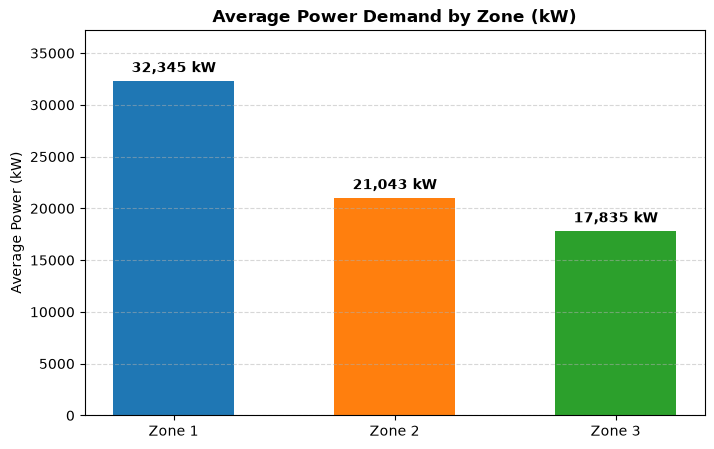

In [121]:
# Average Power Consumed across zones
import matplotlib.pyplot as plt
import seaborn as sns

zone_kw = ['PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']
zone_labels = ['Zone 1', 'Zone 2', 'Zone 3']

fig, ax = plt.subplots( figsize=(8, 5))

Average = df[zone_kw].mean()
bars = ax.bar(zone_labels, Average, color=['#1f77b4', '#ff7f0e', '#2ca02c'], width=0.55)
ax.set_title('Average Power Demand by Zone (kW)', fontweight='bold')
ax.set_ylabel('Average Power (kW)')
ax.set_ylim(0, Average.max() * 1.15)
ax.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 500, f'{height:,.0f} kW',
                 ha='center', va='bottom', fontweight='bold')

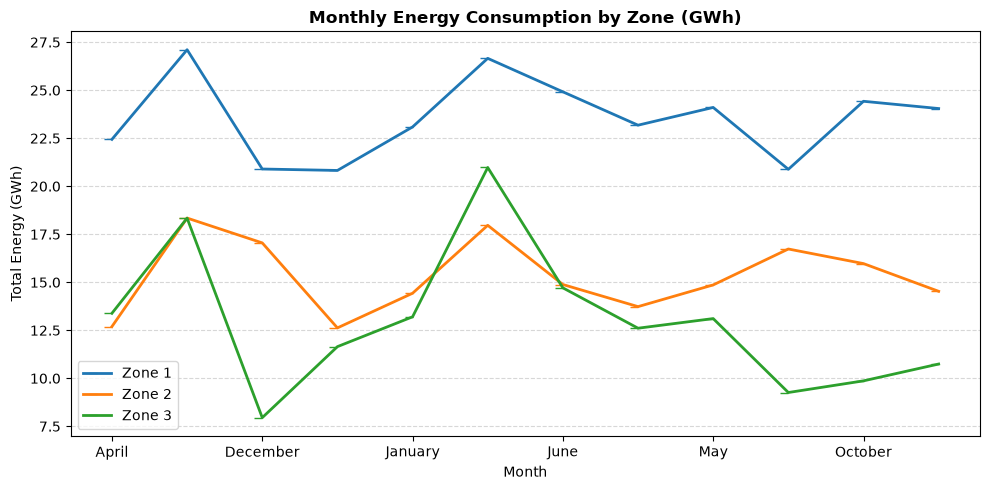

In [127]:
# Monthly consumption pattern accross zones
fig, ax = plt.subplots( figsize=(10, 5))
monthly_gwh = df.groupby('Month')[['Energy_Zone1_kWh', 'Energy_Zone2_kWh', 'Energy_Zone3_kWh']].sum() / 1e6
monthly_gwh.columns = zone_labels
monthly_gwh.plot(kind='line', ax=ax, marker=0, linewidth=2)
ax.set_title('Monthly Energy Consumption by Zone (GWh)', fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Total Energy (GWh)')
ax.tick_params(axis='x', rotation=0)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

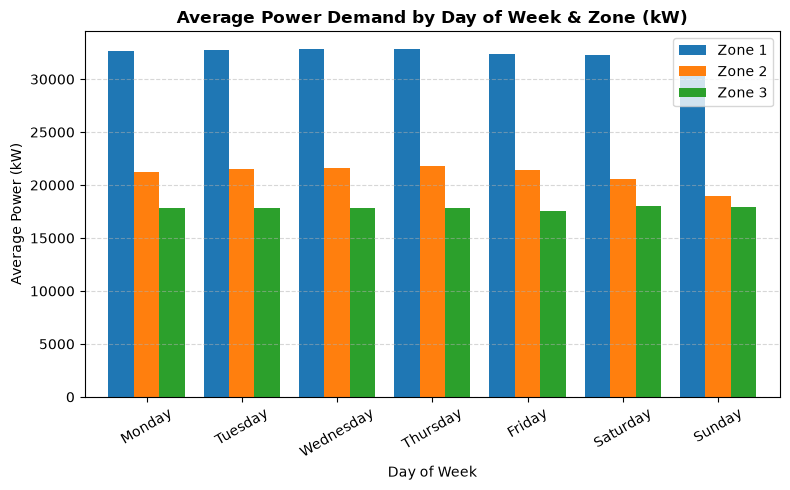

In [128]:
# Day of the Week Consumption
fig, ax = plt.subplots( figsize=(8, 5))
dow_zone = df.groupby('Day_of_Week')[zone_kw].mean().reindex(day_order)
dow_zone.columns = zone_labels
dow_zone.plot(kind='bar', ax=ax, width=0.8)
ax.set_title('Average Power Demand by Day of Week & Zone (kW)', fontweight='bold')
ax.set_xlabel('Day of Week')
ax.set_ylabel('Average Power (kW)')
ax.tick_params(axis='x', rotation=30)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

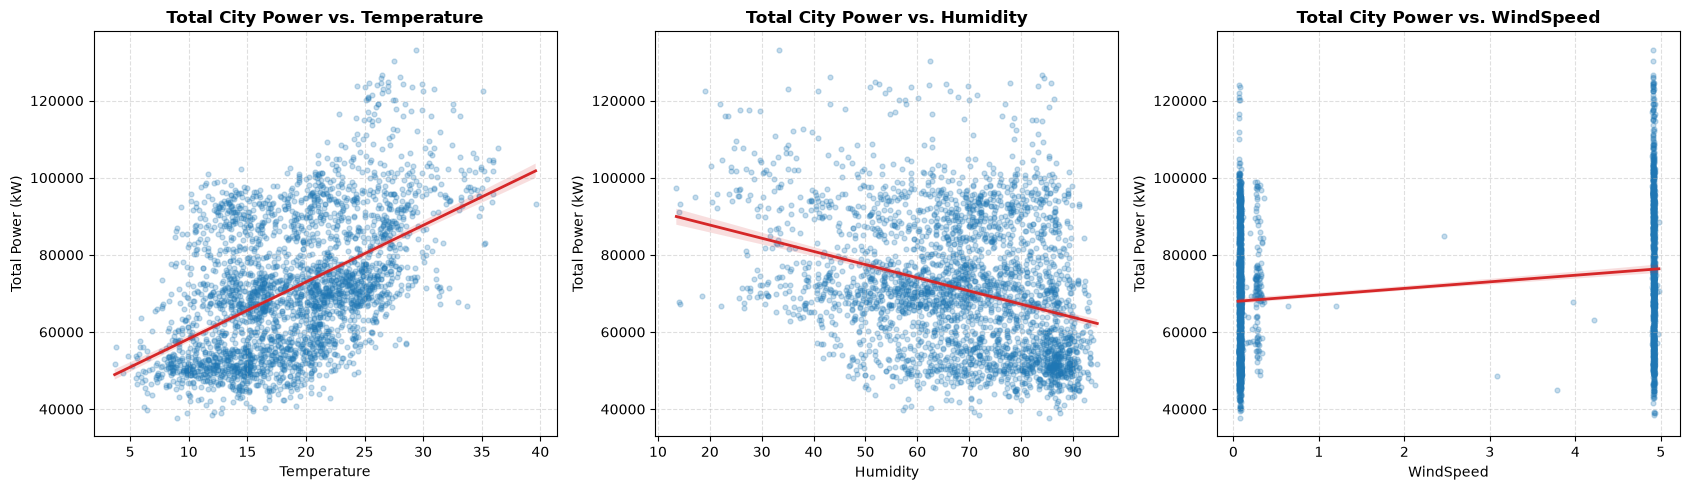

In [130]:
# Enviromental relationship with Total Power consumption
zone_kw = ['PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']
df['Total_Power_kW'] = df[zone_kw].sum(axis=1)

sample_df = df.sample(n=3000, random_state=42)
weather_vars = ['Temperature', 'Humidity', 'WindSpeed',Diffusef]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for idx, var in enumerate(weather_vars):
    sns.regplot(
        data=sample_df, x=var, y='Total_Power_kW', ax=axes[idx],
        scatter_kws={'alpha': 0.25, 's': 12, 'color': '#1f77b4'},
        line_kws={'color': '#d62728', 'linewidth': 2}
    )
    axes[idx].set_title(f'Total City Power vs. {var}', fontweight='bold')
    axes[idx].set_ylabel('Total Power (kW)')
    axes[idx].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()